In [32]:
from sklearn.datasets import load_breast_cancer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf

In [3]:
data = load_breast_cancer()

In [4]:
pd.DataFrame(data.data, columns=data.feature_names).shape

(569, 30)

In [16]:
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.2, random_state=42, stratify=data.target)

In [25]:
model = Sequential([
    Input(shape=(30,)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

In [26]:
model.compile(
    optimizer='adam',
    loss = 'binary_crossentropy',
    metrics=['accuracy']
)

In [35]:
checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath="model.weights.h5",
    save_weights_only = True,
    monitor="val_loss",
    save_best_only = True
)

In [36]:
history = model.fit(
    X_train,
    y_train,
    epochs=40, 
    batch_size=32,
    validation_split=0.2,
    callbacks=[checkpoint_callback]
)

Epoch 1/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9005 - loss: 0.2887 - val_accuracy: 0.8901 - val_loss: 0.3379
Epoch 2/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9323 - loss: 0.1948 - val_accuracy: 0.9670 - val_loss: 0.1906
Epoch 3/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9216 - loss: 0.2636 - val_accuracy: 0.9560 - val_loss: 0.2011
Epoch 4/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9270 - loss: 0.1610 - val_accuracy: 0.9560 - val_loss: 0.1841
Epoch 5/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9426 - loss: 0.1796 - val_accuracy: 0.9121 - val_loss: 0.2055
Epoch 6/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9176 - loss: 0.2074 - val_accuracy: 0.9011 - val_loss: 0.2200
Epoch 7/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9120 - loss: 0.2223 - val_accuracy: 0.9121 - val_loss: 0.2228
Epoch 8/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9129 - loss: 0.2383 - val_accuracy: 0.9341 - val_lo

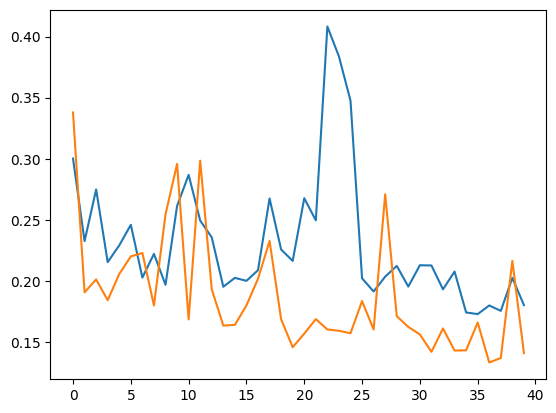

In [37]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

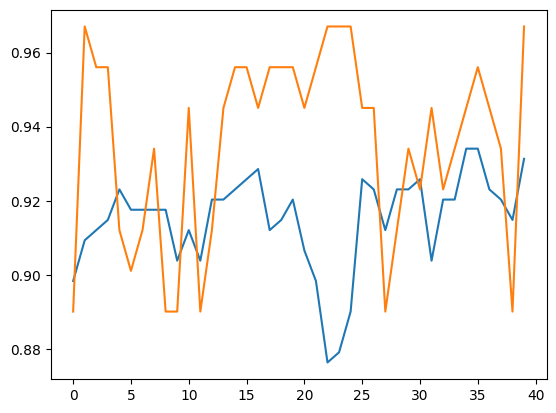

In [38]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

In [39]:
model.evaluate(X_test, y_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9232 - loss: 0.1765 


[0.19568301737308502, 0.9122806787490845]

In [40]:
model.predict(X_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


array([[3.6383898e-13],
       [9.9947178e-01],
       [3.1241980e-01],
       [2.5298429e-01],
       [1.4053038e-12],
       [7.9659075e-01],
       [9.7163880e-01],
       [2.5287078e-05],
       [5.6314201e-07],
       [3.5405547e-09],
       [9.8884755e-01],
       [1.4019999e-05],
       [9.8437834e-01],
       [3.9257124e-08],
       [1.6269129e-04],
       [8.7810224e-01],
       [7.6366007e-01],
       [9.9127138e-01],
       [9.0513790e-01],
       [9.9194598e-01],
       [6.7681615e-04],
       [1.6324989e-03],
       [9.3988216e-01],
       [9.9156898e-01],
       [6.0861737e-01],
       [6.9367081e-01],
       [7.5638199e-23],
       [9.7393441e-01],
       [9.7203463e-01],
       [2.9010636e-01],
       [9.6928132e-01],
       [9.7376794e-01],
       [9.9223262e-01],
       [9.1922653e-01],
       [1.0154822e-08],
       [7.2598505e-01],
       [9.9771082e-01],
       [9.6314102e-01],
       [7.1754217e-01],
       [3.7344892e-09],
       [9.7321248e-01],
       [9.853862

In [41]:
model.load_weights("model.weights.h5")

In [42]:
model.evaluate(X_test, y_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9323 - loss: 0.1501


[0.1815401017665863, 0.9298245906829834]